# Step 1: Environment Setup & Data Loading
Load the dataset generated by `data_collector.py` and strictly validate the project path.

In [11]:
import pandas as pd
import numpy as np
import os
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from typing import cast

# 1. Configurable project root via environment variable, defaulting to current working directory
PROJECT_ROOT = os.environ.get('AI_PIPELINE_ROOT', os.getcwd())
dataset_path = os.path.join(PROJECT_ROOT, 'datasets', 'blink_dataset.csv')

# 2. Explicit existence check with a clear error
if not os.path.exists(dataset_path):
    raise FileNotFoundError(
        f"\n[CRITICAL ERROR] Dataset CSV is missing!\n"
        f"Looked in: {dataset_path}\n"
        f"Fix: Set the 'AI_PIPELINE_ROOT' environment variable to your project directory, "
        f"or ensure your Jupyter server is running inside the 'ai_pipeline' folder."
    )

print(f"Loading raw dataset from: {dataset_path}")

# 3. Load data with type hinting fixes using typing.cast
raw_data = pd.read_csv(dataset_path)  # type: ignore

# 1. Rescue shifted labels: If Label is NaN, the true label was shifted into BoundingBox_Area
mask = raw_data['Label'].isna()
raw_data.loc[mask, 'Label'] = raw_data.loc[mask, 'BoundingBox_Area']

# 2. Drop the BoundingBox_Area column entirely
raw_data = raw_data.drop(columns=['BoundingBox_Area'], errors='ignore')

# 3. Clean up any genuinely corrupted rows
raw_data = raw_data.dropna(subset=['Label'])

df = cast(pd.DataFrame, raw_data)

print("\n--- RAW DATA COUNTS ---")
print(df['Label'].value_counts().sort_index())

Loading raw dataset from: C:\Users\ahmed\Documents\grad_project\ai_pipeline\gaze_intent\datasets\blink_dataset.csv

--- RAW DATA COUNTS ---
Label
0.0    22855
1.0    18682
2.0    19097
3.0    19747
Name: count, dtype: int64


# Step 2: Transition Frame Cleaning
In live video, the frames where an eye is "half-closed" pollute the dataset. We use a strict EAR threshold to identify these ambiguous transition frames and safely reassign them to the Neutral class.

In [12]:
# Force the threshold to the mathematical midpoint of a normalized open/closed eye
# TODO: This threshold must be recalculated by observing the new CSV data, because pure 3D EAR values will have a completely different numerical scale than the old 2D pixel-scaled values.
threshold = 0.55

print(f"Dynamically calculated user threshold: {threshold:.3f}")

# --- AGGRESSIVE CLEANING RULES ---
# Identify frames that violate their intended label's ideal geometric state
dirty_neutral = (df['Label'] == 0) & ((df['Left_EAR'] < threshold) | (df['Right_EAR'] < threshold))
dirty_left = (df['Label'] == 1) & ((df['Left_EAR'] > threshold) | (df['Right_EAR'] < threshold))
dirty_right = (df['Label'] == 2) & ((df['Right_EAR'] > threshold) | (df['Left_EAR'] < threshold))
dirty_closure = (df['Label'] == 3) & ((df['Left_EAR'] > threshold) | (df['Right_EAR'] > threshold))

dirty_frames = dirty_neutral | dirty_left | dirty_right | dirty_closure
print(f"Total dirty transition frames permanently deleted: {dirty_frames.sum()}")

# DROP the dirty frames entirely instead of reassigning them
df = df[~dirty_frames]

print("\n--- CLEAN DATA COUNTS ---")
print(df['Label'].value_counts().sort_index())

Dynamically calculated user threshold: 0.550
Total dirty transition frames permanently deleted: 48765

--- CLEAN DATA COUNTS ---
Label
0.0    20351
1.0     2731
2.0     2206
3.0     6328
Name: count, dtype: int64


# Step 3: Feature Selection & Model Training
Isolate the specific temporal features and train a lightweight Random Forest model capped at a depth of 10 to ensure real-time C++ performance.

In [13]:
# Define Features (X) and Labels (y) explicitly to avoid data leakage
X = df[['Left_EAR', 'Left_Min_10f', 'Left_Var_10f',
        'Right_EAR', 'Right_Min_10f', 'Right_Var_10f']]
y = df['Label']

# Split the data: 80% for training, 20% for testing the accuracy
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training Random Forest Classifier...")
# max_depth=10 prevents overfitting and keeps the model execution blazing fast
clf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
clf.fit(X_train, y_train)
print("Training Complete!")

Training Random Forest Classifier...
Training Complete!


# Step 4: Model Evaluation
Verify that the model isn't just defaulting to "Neutral" by checking its precision and recall across all 4 specific states using a confusion matrix.

--- MODEL ACCURACY: 99.98% ---

              precision    recall  f1-score   support

     Neutral       1.00      1.00      1.00      4071
   Left Wink       1.00      1.00      1.00       546
  Right Wink       1.00      1.00      1.00       441
     Closure       1.00      1.00      1.00      1266

    accuracy                           1.00      6324
   macro avg       1.00      1.00      1.00      6324
weighted avg       1.00      1.00      1.00      6324



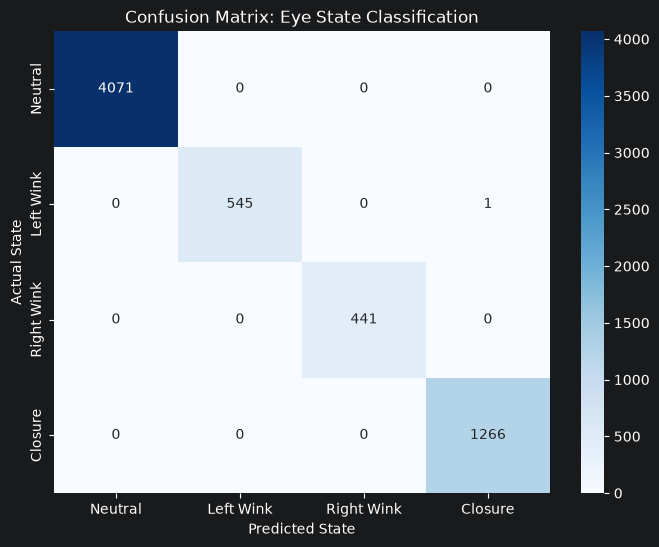

In [14]:
# Test the model
y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"--- MODEL ACCURACY: {accuracy * 100:.2f}% ---\n")
print(classification_report(y_test, y_pred, target_names=['Neutral', 'Left Wink', 'Right Wink', 'Closure']))

# Visualize the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Neutral', 'Left Wink', 'Right Wink', 'Closure'],
            yticklabels=['Neutral', 'Left Wink', 'Right Wink', 'Closure'])

plt.title('Confusion Matrix: Eye State Classification')
plt.ylabel('Actual State')
plt.xlabel('Predicted State')
plt.show()

# Step 5: Export for C++ Integration
Serialize the trained model into a `.dll` file so the production `gaze_intent.py` module can load it instantly.

In [15]:
import os
import treelite
import tl2cgen

# Resolve relative to the same explicit project root
PROJECT_ROOT = os.environ.get('AI_PIPELINE_ROOT', os.getcwd())
os.makedirs(os.path.join(PROJECT_ROOT, 'models'), exist_ok=True)
model_output_path = os.path.join(PROJECT_ROOT, 'models', 'models/gesture_model.dll')

print("Translating Wink Classifier to native C code...")
# 1. Import from scikit-learn using treelite
model_treelite = treelite.sklearn.import_model(clf)

print("Compiling dynamic library...")
# 2. Compile using tl2cgen instead of treelite
tl2cgen.export_lib(
    model_treelite,
    toolchain='msvc',
    libpath=model_output_path,
    params={'parallel_comp': 8},
    verbose=True
)

print(f"\n[SUCCESS] Production DLL compiled and saved to:\n{model_output_path}")


Translating Wink Classifier to native C code...
Compiling dynamic library...
[17:52:14] D:\a\tl2cgen\tl2cgen\src\compiler\ast\split.cc:35: Parallel compilation enabled; member trees will be divided into 8 translation units.
Compiling sources files in directory C:\Users\ahmed\AppData\Local\Temp\tmpxgzeucl5 into object files (*.obj)...
Generating dynamic shared library C:\Users\ahmed\AppData\Local\Temp\tmpxgzeucl5\predictor.dll...
Generated shared library in 23.90 seconds

[SUCCESS] Production DLL compiled and saved to:
C:\Users\ahmed\Documents\grad_project\ai_pipeline\gaze_intent\gesture_model.dll
